# Main notebook: Home Credit Default Risk (GCI Global 2026)

This notebook builds the model step by step, following `PLAN.md`. Every change is **measured** with the same cross-validation, so we always know whether it helped or hurt.

- **Phase 2:** preprocessing based on the findings in `eda.ipynb`.
- **Phase 4 (baseline):** LightGBM with 5-fold stratified cross-validation.

> **How to read the scores.** There are two different numbers:
> 1. **Local score (CV AUC):** computed here, on `train.csv`, by hiding part of the data from the model and checking how well it ranks it. Free, instant, unlimited.
> 2. **Public Leaderboard score:** computed by Omnicampus when you upload the CSV, on part of `test.csv`.
>
> The local score is your **practice exam** and the leaderboard is the **mock exam**: if a change raises the CV AUC, it will usually raise the leaderboard score too.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from pathlib import Path

SEED = 42
np.random.seed(SEED)

train = pd.read_csv("input/train.csv")
test = pd.read_csv("input/test.csv")
sample_sub = pd.read_csv("input/sample_submission.csv")
print("train:", train.shape, "| test:", test.shape)

sns.set_theme(style="whitegrid", rc={"axes.titlelocation": "left", "axes.titlesize": 12,
                                     "axes.titleweight": "bold", "grid.color": "#e6e5e0"})

train: (171202, 34) | test: (61500, 33)


## 1. Phase 2: preprocessing

Each step comes from a finding in `eda.ipynb` (section number in brackets).

| Step | Why (EDA) |
|---|---|
| `DAYS_EMPLOYED == 365243` → `NaN` + flag `DAYS_EMPLOYED_ANOM` | It is a code for pensioners, not a real number of days (§7) |
| `OWN_CAR_AGE >= 64` → `NaN` + flag `OWN_CAR_AGE_ANOM` | 64 and 65 are codes, not real car ages (§8) |
| `"XNA"` and `"Unknown"` → `NaN` | Missing values disguised as categories (§9, §10) |
| Drop `FLAG_MOBIL` | Constant: every client but one has 1 (§11) |
| Text columns → `category` type | LightGBM handles categories natively, no one-hot needed |
| **No** mean imputation, **no** scaling | LightGBM uses `NaN` as information (§3) and trees do not need scaling |

> **Golden rule:** train and test go through **exactly the same function**. We process them together so that the categories are identical in both, like translating two documents with the same dictionary.

In [2]:
def preprocess(df, drop_cols=("FLAG_MOBIL",)):
    """Phase 2 cleaning. Applied identically to train and test."""
    df = df.copy()

    # Codes that are not real values -> NaN, keeping the information in a flag
    anom = df["DAYS_EMPLOYED"] == 365243
    df["DAYS_EMPLOYED_ANOM"] = anom.astype(int)
    df.loc[anom, "DAYS_EMPLOYED"] = np.nan

    car_anom = df["OWN_CAR_AGE"] >= 64
    df["OWN_CAR_AGE_ANOM"] = car_anom.astype(int)
    df.loc[car_anom, "OWN_CAR_AGE"] = np.nan

    # Disguised missing values
    df = df.replace({"XNA": np.nan, "Unknown": np.nan})

    # Useless columns
    df = df.drop(columns=[c for c in drop_cols if c in df.columns])
    return df


def build_xy(clean=True, drop_cols=("FLAG_MOBIL",)):
    """Process train and test together and return X, y, X_test."""
    full = pd.concat([train, test], ignore_index=True)
    if clean:
        full = preprocess(full, drop_cols=drop_cols)
    for c in full.select_dtypes(exclude="number").columns:
        full[c] = full[c].astype("category")
    feats = [c for c in full.columns if c not in ("SK_ID_CURR", "TARGET")]
    X = full.loc[: len(train) - 1, feats].reset_index(drop=True)
    X_test = full.loc[len(train):, feats].reset_index(drop=True)
    return X, train["TARGET"], X_test

X, y, X_test = build_xy()
print("Features:", X.shape[1])
X.head(3)

Features: 33


,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,...,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,DAYS_EMPLOYED_ANOM,OWN_CAR_AGE_ANOM
0,Cash loans,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,Married,...,NaN,0.372591,NaN,-292.0,NaN,NaN,NaN,NaN,0,0
1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,Married,...,NaN,0.449567,0.553165,-617.0,0.0,0.0,0.0,1.0,1,0
2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,Married,...,NaN,0.569503,NaN,-542.0,NaN,NaN,NaN,NaN,0,0


## 2. Phase 4 (baseline): LightGBM + 5-fold cross-validation

**Why LightGBM:** it is a set of many small decision trees, each one correcting the mistakes of the previous ones. It handles `NaN` and categories by itself and is the usual winner on tabular data.

**Why 5 folds instead of the tutorial's single 70/30 split:** with one split, the score depends on the luck of which clients ended up in validation. With 5 folds, every client is in validation exactly once and we average. It is like taking 5 mock exams instead of 1: the average grade is much more reliable.

**Early stopping:** the model keeps adding trees while the validation AUC improves and stops 100 trees after it stops improving. This prevents memorising the training data (overfitting).

The function returns:
- **OOF AUC** (out-of-fold): the AUC over all clients, each predicted by the model that did *not* see them. **This is our reference score.**
- The **test prediction**: the average of the 5 models.

In [3]:
PARAMS = dict(
    objective="binary", metric="auc",
    learning_rate=0.05, num_leaves=31, min_child_samples=50,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
    n_estimators=5000, random_state=SEED, n_jobs=-1, verbose=-1,
)

def run_cv(X, y, X_test, params=PARAMS, n_splits=5, verbose=True):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    oof = np.zeros(len(X))
    pred_test = np.zeros(len(X_test))
    fold_auc, importances = [], []
    for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y)):
        model = lgb.LGBMClassifier(**params)
        model.fit(X.iloc[tr_idx], y.iloc[tr_idx],
                  eval_set=[(X.iloc[va_idx], y.iloc[va_idx])],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
        oof[va_idx] = model.predict_proba(X.iloc[va_idx])[:, 1]
        pred_test += model.predict_proba(X_test)[:, 1] / n_splits
        fold_auc.append(roc_auc_score(y.iloc[va_idx], oof[va_idx]))
        importances.append(pd.Series(model.booster_.feature_importance("gain"), index=X.columns))
        if verbose:
            print(f"Fold {fold + 1}: AUC {fold_auc[-1]:.4f}  ({model.best_iteration_} trees)")
    auc = roc_auc_score(y, oof)
    if verbose:
        print(f"OOF AUC: {auc:.4f}   (fold std: {np.std(fold_auc):.4f})")
    return dict(auc=auc, fold_std=np.std(fold_auc), oof=oof, pred_test=pred_test,
                importance=pd.concat(importances, axis=1).mean(axis=1).sort_values(ascending=False))

## 3. Experiments: does the preprocessing help?

We compare, always with the same folds and the same model:

| # | Version |
|---|---|
| 0 | Tutorial: Random Forest, 5 features, single 70/30 split (reference value, measured separately: **0.669**) |
| 1 | LightGBM, **all** features, **no** cleaning |
| 2 | LightGBM + Phase 2 cleaning |
| 3 | LightGBM + cleaning + dropping `FLAG_EMP_PHONE` (redundant with the anomaly flag, EDA §7) |

In [4]:
log = [dict(exp=0, version="Tutorial (RF, 5 features, 70/30 split)", cv_auc=0.669, fold_std=np.nan)]

print("=== Exp 1: all features, no cleaning ===")
r1 = run_cv(*build_xy(clean=False))
log.append(dict(exp=1, version="LightGBM, all features, no cleaning", cv_auc=r1["auc"], fold_std=r1["fold_std"]))

print("\n=== Exp 2: + Phase 2 cleaning ===")
r2 = run_cv(*build_xy(clean=True))
log.append(dict(exp=2, version="+ Phase 2 cleaning", cv_auc=r2["auc"], fold_std=r2["fold_std"]))

print("\n=== Exp 3: + drop FLAG_EMP_PHONE ===")
r3 = run_cv(*build_xy(clean=True, drop_cols=("FLAG_MOBIL", "FLAG_EMP_PHONE")))
log.append(dict(exp=3, version="+ drop FLAG_EMP_PHONE", cv_auc=r3["auc"], fold_std=r3["fold_std"]))

log_df = pd.DataFrame(log).set_index("exp")
log_df["vs_previous"] = log_df["cv_auc"].diff()
log_df.round(4)

=== Exp 1: all features, no cleaning ===


Fold 1: AUC 0.7453  (202 trees)


Fold 2: AUC 0.7501  (276 trees)


Fold 3: AUC 0.7542  (345 trees)


Fold 4: AUC 0.7462  (293 trees)


Fold 5: AUC 0.7504  (227 trees)
OOF AUC: 0.7492   (fold std: 0.0032)

=== Exp 2: + Phase 2 cleaning ===


... (7 outputs left out)

Fold 3: AUC 0.7539  (153 trees)


Fold 4: AUC 0.7453  (216 trees)


Fold 5: AUC 0.7524  (221 trees)
OOF AUC: 0.7493   (fold std: 0.0035)


,version,cv_auc,fold_std,vs_previous
exp,,,,
0,"Tutorial (RF, 5 features, 70/30 split)",0.6690,NaN,NaN
1,"LightGBM, all features, no cleaning",0.7492,0.0032,0.0802
2,+ Phase 2 cleaning,0.7499,0.0028,0.0007
3,+ drop FLAG_EMP_PHONE,0.7493,0.0035,-0.0006


**How to read the table:**
- **0.669 → 0.749:** the big jump comes from using **all** the variables and **LightGBM** instead of 5 variables and a Random Forest. This is the step that moves you up the leaderboard.
- **Cleaning (exp 2):** +0.0007. It is a real but small improvement: trees already "isolated" the codes on their own, because a tree can split at `DAYS_EMPLOYED > 300000`. We keep the cleaning anyway, because Phase 3 needs it: a ratio like `DAYS_EMPLOYED / DAYS_BIRTH` would be nonsense with the 365243 code inside.
- **Dropping `FLAG_EMP_PHONE` (exp 3):** -0.0006, so we **keep** the column.

> **Noise vs signal.** The AUC varies about ±0.003 between folds (`fold_std`). Differences of 0.0005 are within that noise, like two students whose grades differ by 0.1 points on one exam: you cannot say who is better. From Phase 3 on we look for changes of **+0.002 or more**.

## 4. Model chosen for this phase: experiment 2

**Which variables does the model use most?** Importance by *gain*: how much each variable improved the trees in total. It confirms the EDA: the `EXT_SOURCE` scores on top, then age and the amounts.

Path in the chart tree: compare many categories → **sorted horizontal bars**.

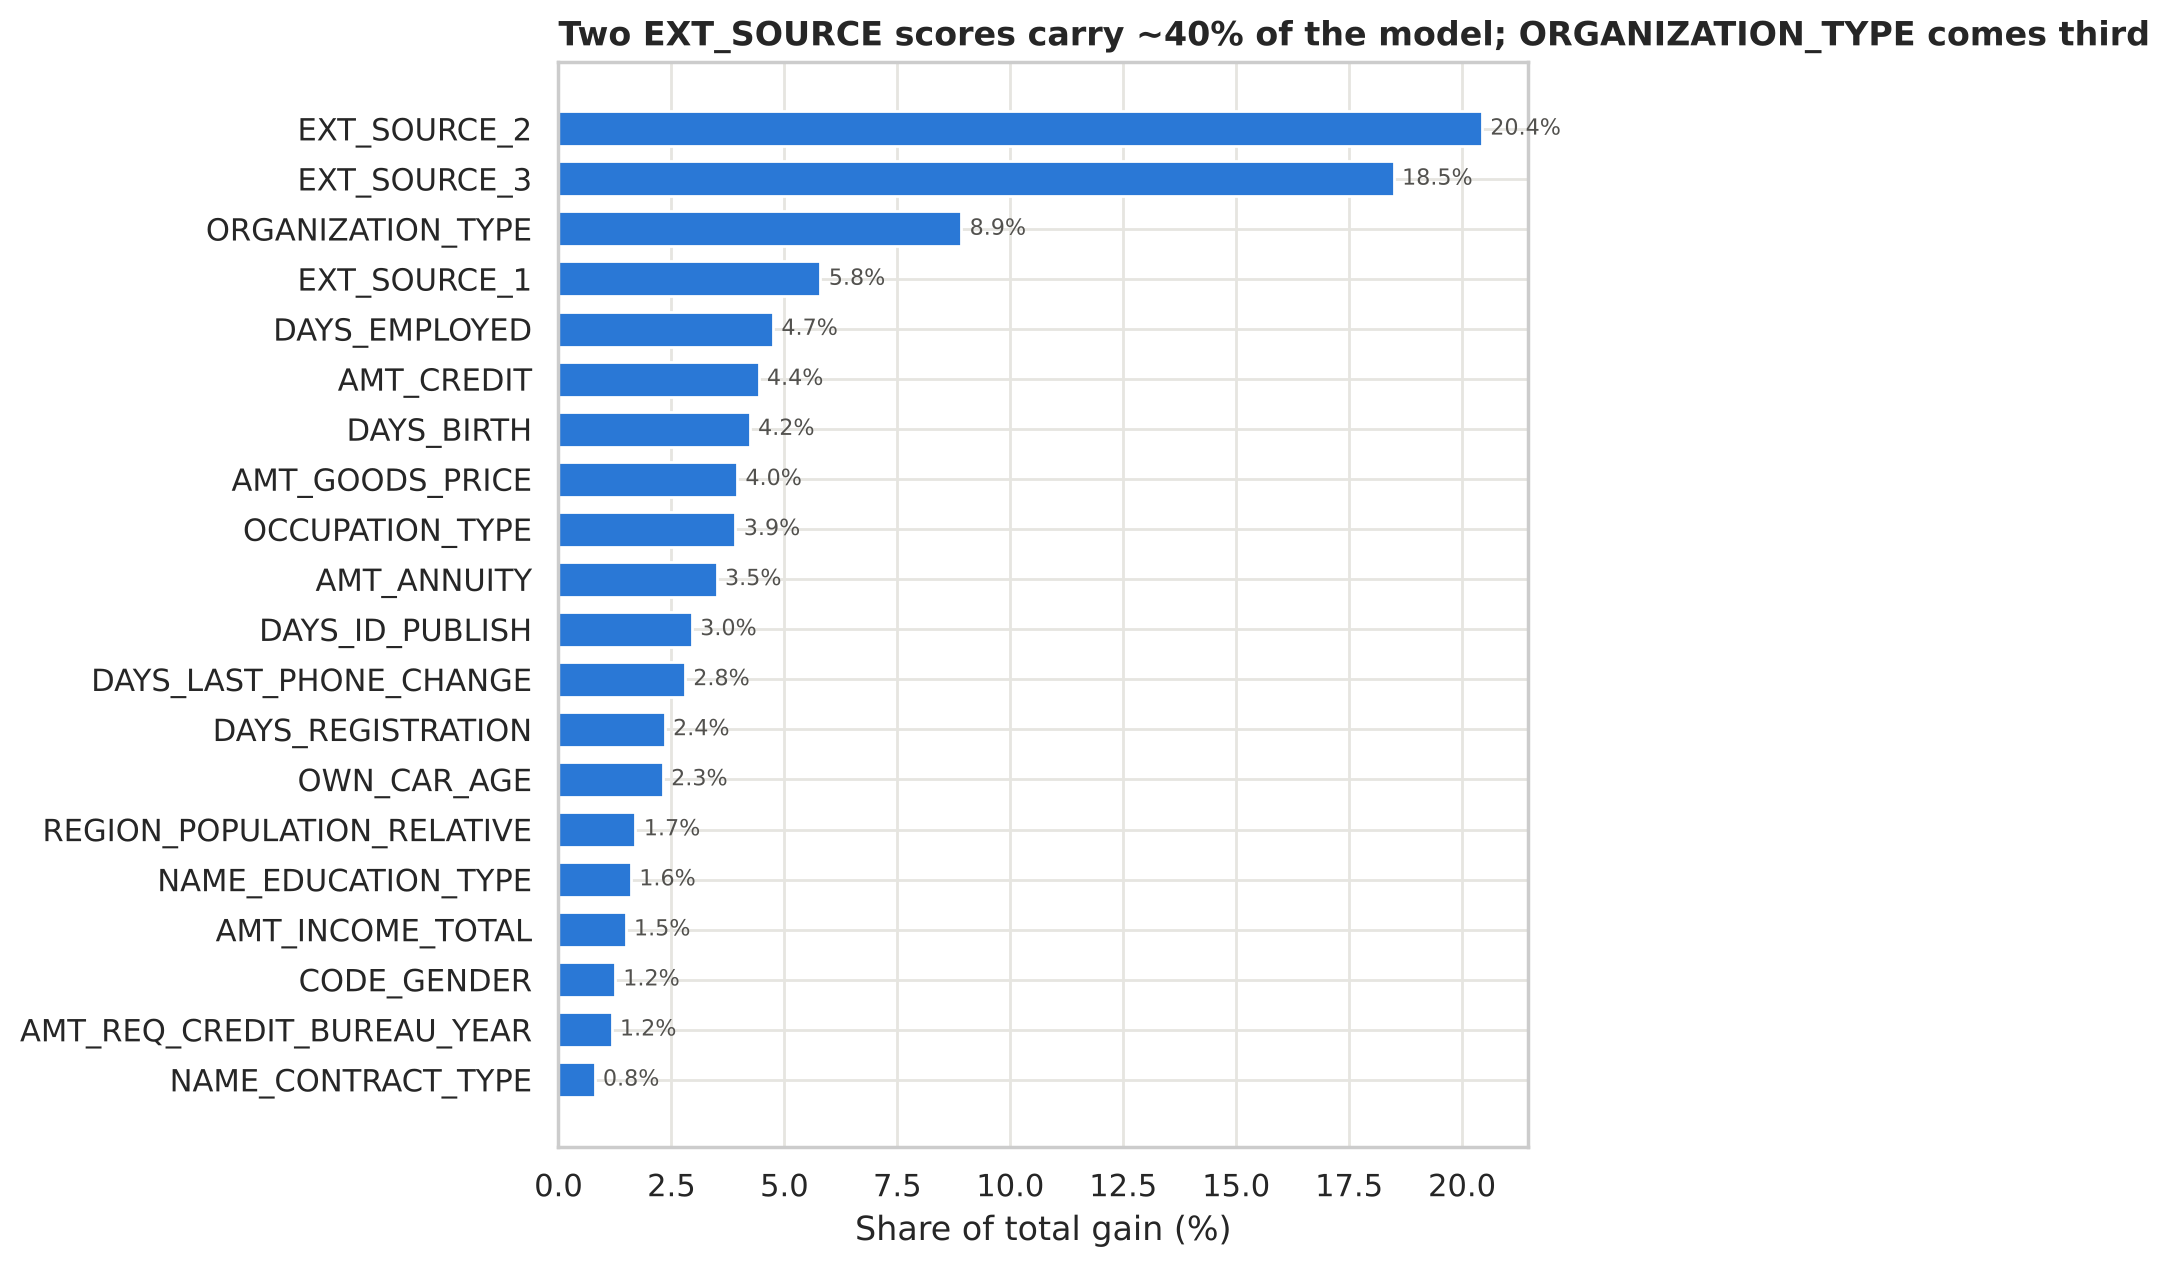

In [5]:
best = r2
imp = (best["importance"] / best["importance"].sum() * 100).head(20).sort_values()

fig, ax = plt.subplots(figsize=(8, 6.5))
bars = ax.barh(imp.index, imp.values, color="#2a78d6", height=0.7)
ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=8, color="#52514e")
ax.set_xlabel("Share of total gain (%)")
ax.set_title("Two EXT_SOURCE scores carry ~40% of the model; ORGANIZATION_TYPE comes third")
plt.tight_layout(); plt.show()

**What we see:**
- `EXT_SOURCE_2` and `EXT_SOURCE_3` carry almost 40% of the total gain, as the EDA predicted.
- `ORGANIZATION_TYPE` is **third** (8.9%). Careful: with 58 categories, a tree has many ways to split it, and *gain* importance tends to inflate variables like this. It may be useful, or the model may be memorising small sectors. We will compare it against **Count Encoding** in Phase 3.
- `AMT_CREDIT`, `AMT_GOODS_PRICE` and `AMT_ANNUITY` rank in the middle, although on their own they barely separated (EDA §4). The trees are **combining** them, for example "high credit **and** low goods price". That is exactly what we will make explicit in Phase 3 with ratios.

## 5. Submission file

Same format and same row order as `sample_submission.csv`. We save it with a version name so we never overwrite an earlier one.

In [6]:
sub = sample_sub.copy()
assert (sub["SK_ID_CURR"].values == test["SK_ID_CURR"].values).all()   # same order as test
sub["TARGET"] = best["pred_test"]

assert sub["TARGET"].between(0, 1).all() and sub["TARGET"].notna().all()
assert len(sub) == len(sample_sub)

Path("output").mkdir(exist_ok=True)
sub.to_csv("output/submission_v1_lgbm_phase2.csv", index=False)
print(f"Saved output/submission_v1_lgbm_phase2.csv  |  CV AUC {best['auc']:.4f}")
sub.head()

Saved output/submission_v1_lgbm_phase2.csv  |  CV AUC 0.7499


,SK_ID_CURR,TARGET
0,171202,0.026249
1,171203,0.152647
2,171204,0.121009
3,171205,0.105164
4,171206,0.184008


## 6. Phase 3: feature engineering

We create new variables in **groups**, test each group with the same CV, and keep only what improves the score by more than the noise (about ±0.003 between folds).

| Group | New variables | Idea |
|---|---|---|
| A | `EXT_MEAN`, `EXT_MIN`, `EXT_MAX`, `EXT_STD`, `EXT_PROD`, `EXT_N_MISSING`, `EXT_WEIGHTED` | Combine the three strongest scores (EDA §4-5) |
| B | `CREDIT_INCOME_RATIO`, `ANNUITY_INCOME_RATIO`, `CREDIT_TERM`, `GOODS_CREDIT_RATIO`, `CREDIT_GOODS_DIFF`, `INCOME_PER_PERSON` | Amounts *relative to each other* (EDA §8) |
| C | `EMPLOYED_BIRTH_RATIO`, `ID_PUBLISH_BIRTH_RATIO`, `REGISTRATION_BIRTH_RATIO`, `PHONE_BIRTH_RATIO` | Time variables relative to age (EDA §6) |
| D | `N_MISSING` | Missing values carry risk (EDA §3) |
| E | `ORGANIZATION_TYPE_COUNT`, `OCCUPATION_TYPE_COUNT` | Count Encoding as an alternative view of big categories (EDA §10) |

> **Analogy:** a banker does not judge you only by your salary or only by the loan amount. What matters is the **relationship**: €10,000 is a lot for someone earning €15,000 a year and very little for someone earning €100,000.

In [7]:
EXT = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]

def add_ext(df):          # group A
    e = df[EXT]
    df["EXT_MEAN"] = e.mean(axis=1)
    df["EXT_MIN"] = e.min(axis=1)
    df["EXT_MAX"] = e.max(axis=1)
    df["EXT_STD"] = e.std(axis=1)
    df["EXT_PROD"] = e.prod(axis=1, min_count=1)
    df["EXT_N_MISSING"] = e.isna().sum(axis=1)
    df["EXT_WEIGHTED"] = (e.fillna(e.mean()) * [2, 1, 3]).sum(axis=1)

def add_ratios(df):       # group B
    df["CREDIT_INCOME_RATIO"] = df["AMT_CREDIT"] / df["AMT_INCOME_TOTAL"]     # how many yearly salaries they borrow
    df["ANNUITY_INCOME_RATIO"] = df["AMT_ANNUITY"] / df["AMT_INCOME_TOTAL"]   # share of income going to the instalment
    df["CREDIT_TERM"] = df["AMT_ANNUITY"] / df["AMT_CREDIT"]                  # instalment / loan ~ 1 / number of payments
    df["GOODS_CREDIT_RATIO"] = df["AMT_GOODS_PRICE"] / df["AMT_CREDIT"]       # how much of the loan buys the goods
    df["CREDIT_GOODS_DIFF"] = df["AMT_CREDIT"] - df["AMT_GOODS_PRICE"]        # money borrowed beyond the goods price
    df["INCOME_PER_PERSON"] = df["AMT_INCOME_TOTAL"] / df["CNT_FAM_MEMBERS"]

def add_time_ratios(df):  # group C
    for c in ["DAYS_EMPLOYED", "DAYS_ID_PUBLISH", "DAYS_REGISTRATION", "DAYS_LAST_PHONE_CHANGE"]:
        name = {"DAYS_EMPLOYED": "EMPLOYED", "DAYS_ID_PUBLISH": "ID_PUBLISH",
                "DAYS_REGISTRATION": "REGISTRATION", "DAYS_LAST_PHONE_CHANGE": "PHONE"}[c]
        df[f"{name}_BIRTH_RATIO"] = df[c] / df["DAYS_BIRTH"]

def add_n_missing(df):    # group D
    df["N_MISSING"] = df.drop(columns=["TARGET"]).isna().sum(axis=1)

def add_counts(df):       # group E (counts over train + test, no TARGET involved)
    for c in ["ORGANIZATION_TYPE", "OCCUPATION_TYPE"]:
        df[f"{c}_COUNT"] = df[c].map(df[c].value_counts())

def add_credit_term(df):  # only the best ratio (for the ablation test)
    df["CREDIT_TERM"] = df["AMT_ANNUITY"] / df["AMT_CREDIT"]


def build_xy_fe(groups=(), drop_cols=("FLAG_MOBIL",)):
    """Phase 2 cleaning + the chosen feature groups."""
    full = preprocess(pd.concat([train, test], ignore_index=True), drop_cols=drop_cols)
    for g in groups:
        g(full)
    for c in full.select_dtypes(exclude="number").columns:
        full[c] = full[c].astype("category")
    feats = [c for c in full.columns if c not in ("SK_ID_CURR", "TARGET")]
    X = full.loc[: len(train) - 1, feats].reset_index(drop=True)
    X_test = full.loc[len(train):, feats].reset_index(drop=True)
    return X, train["TARGET"], X_test

### 6.1 Each group on its own (on top of experiment 2)

Testing groups one by one tells us **which idea works**, not just whether "everything together" works. It is like changing one ingredient at a time in a recipe.

In [8]:
experiments = {
    "A: EXT_SOURCE combinations": [add_ext],
    "B: financial ratios": [add_ratios],
    "C: time ratios": [add_time_ratios],
    "D: N_MISSING": [add_n_missing],
    "E: count encoding": [add_counts],
}
results = {}
for name, groups in experiments.items():
    r = run_cv(*build_xy_fe(groups), verbose=False)
    results[name] = r
    print(f"{name:32s} CV AUC {r['auc']:.4f}  ({r['auc'] - r2['auc']:+.4f} vs exp 2)")

A: EXT_SOURCE combinations       CV AUC 0.7495  (-0.0004 vs exp 2)


B: financial ratios              CV AUC 0.7577  (+0.0078 vs exp 2)


C: time ratios                   CV AUC 0.7491  (-0.0008 vs exp 2)


D: N_MISSING                     CV AUC 0.7499  (-0.0000 vs exp 2)


E: count encoding                CV AUC 0.7497  (-0.0002 vs exp 2)


**Only group B (financial ratios) clearly improves**: about +0.008, almost three times the fold noise. A, C, D and E stay within ±0.0008, which is noise.

Why do the `EXT_SOURCE` combinations not help, when they are the strongest variables? Because the trees **already combine them on their own**: a tree can split on `EXT_SOURCE_3` and then on `EXT_SOURCE_2`. A ratio is different: to approximate "annuity divided by credit", a tree would need many, many splits, so giving it the ratio directly saves it a lot of work.

### 6.2 Do the other groups help once the ratios are in?

In [9]:
rB = results["B: financial ratios"]
for name, groups in {"B + A": [add_ratios, add_ext], "B + C": [add_ratios, add_time_ratios],
                     "B + D": [add_ratios, add_n_missing], "B + E": [add_ratios, add_counts]}.items():
    r = run_cv(*build_xy_fe(groups), verbose=False)
    print(f"{name:8s} CV AUC {r['auc']:.4f}  ({r['auc'] - rB['auc']:+.4f} vs B alone)")

B + A    CV AUC 0.7574  (-0.0003 vs B alone)


B + C    CV AUC 0.7572  (-0.0005 vs B alone)


B + D    CV AUC 0.7579  (+0.0003 vs B alone)


B + E    CV AUC 0.7572  (-0.0005 vs B alone)


None of them adds anything meaningful on top of B (all within ±0.0005). Following the rule "keep only what beats the noise", **we keep group B alone**: fewer variables, same score, less risk of overfitting.

### 6.3 Which ratio does the work? (ablation)

An **ablation** test removes or isolates one piece to measure its contribution, like taking one player off the pitch to see how much the team misses them.

In [10]:
r_term = run_cv(*build_xy_fe([add_credit_term]), verbose=False)
print(f"Only CREDIT_TERM:          CV AUC {r_term['auc']:.4f}  ({r_term['auc'] - r2['auc']:+.4f} vs exp 2)")
print(f"All six ratios (group B):  CV AUC {rB['auc']:.4f}  ({rB['auc'] - r2['auc']:+.4f} vs exp 2)")

Only CREDIT_TERM:          CV AUC 0.7569  (+0.0070 vs exp 2)
All six ratios (group B):  CV AUC 0.7577  (+0.0078 vs exp 2)


**`CREDIT_TERM` alone gives almost 90% of the improvement.** `AMT_ANNUITY / AMT_CREDIT` is the instalment divided by the loan, so its inverse (`AMT_CREDIT / AMT_ANNUITY`) is roughly the **number of payments**, i.e. the loan length (0.05 ≈ 20 payments, 0.10 ≈ 10 payments). The values range from about 8 to 47, which fits monthly payments.

Path in the chart tree: one numeric variable binned into ordered groups (like age, EDA §6) → **vertical bars** of the default rate per decile.

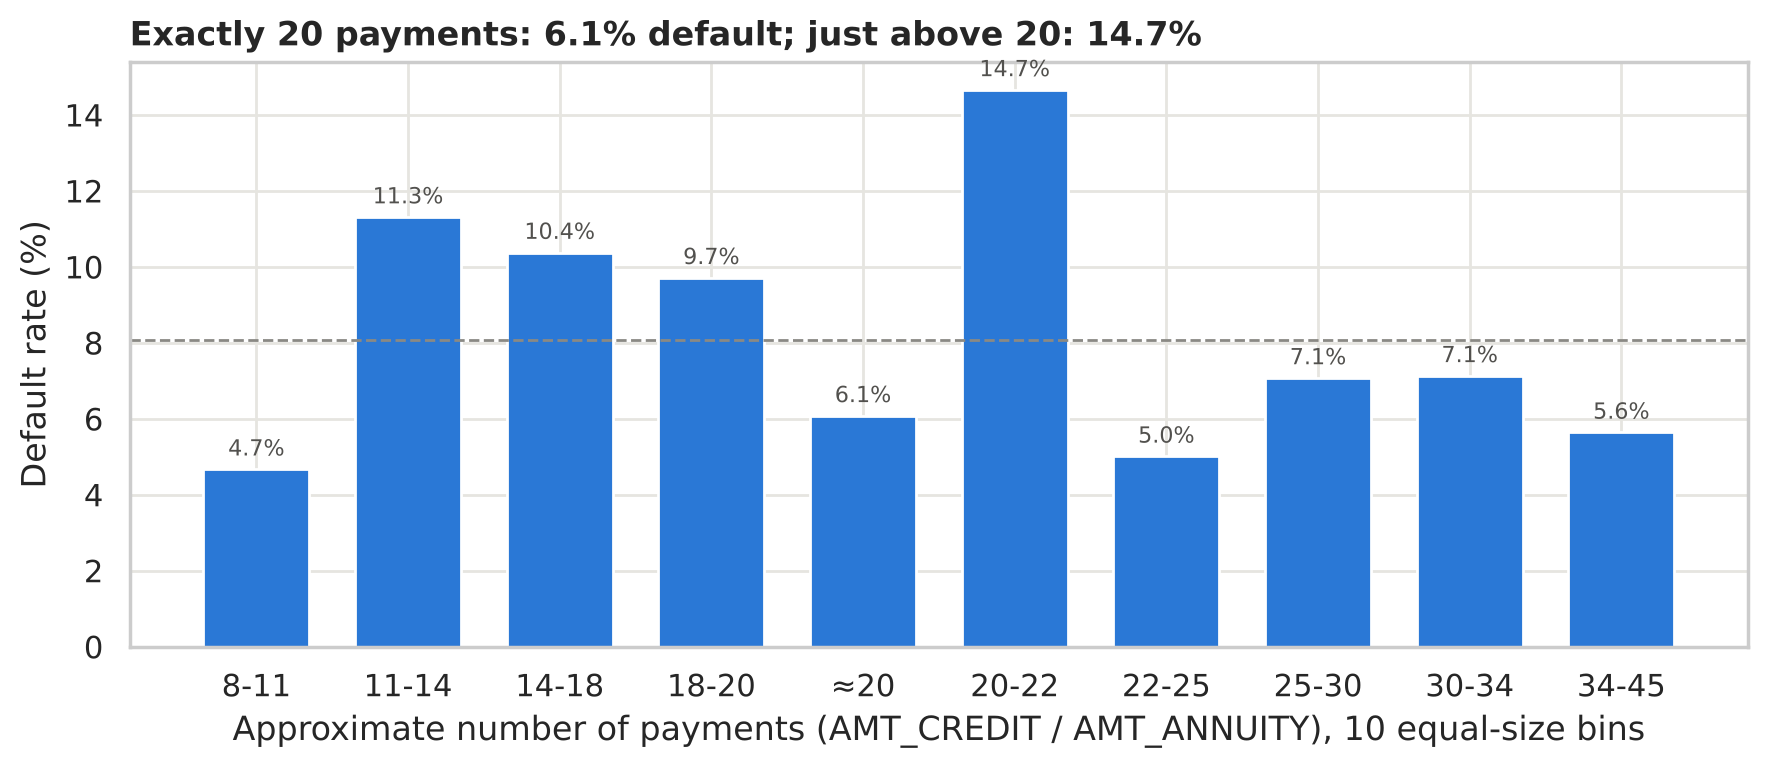

In [11]:
n_payments = train["AMT_CREDIT"] / train["AMT_ANNUITY"]          # = 1 / CREDIT_TERM
g = train.groupby(pd.qcut(n_payments, 10), observed=True)["TARGET"].mean() * 100
labels = [f"≈{iv.left:.0f}" if round(iv.left) == round(iv.right) else f"{iv.left:.0f}-{iv.right:.0f}"
          for iv in g.index]

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(labels, g.values, color="#2a78d6", width=0.7)
ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=8, color="#52514e")
ax.axhline(train["TARGET"].mean() * 100, color="#8a8984", ls="--", lw=1)
ax.set_xlabel("Approximate number of payments (AMT_CREDIT / AMT_ANNUITY), 10 equal-size bins")
ax.set_ylabel("Default rate (%)")
ax.set_title("Exactly 20 payments: 6.1% default; just above 20: 14.7%")
plt.tight_layout(); plt.show()

**What we see:** the default rate jumps up and down with the loan length instead of following a straight line:
- Loans with **exactly 20 payments** are so common that they fill a whole bin (≈20), which suggests a standard loan product. Their default rate is **6.1%**.
- Right next to them, loans with **20 to 22 payments** reach **14.7%**, the highest of all.
- The shortest loans (8-11 payments) are the safest (4.7%).

Neither `AMT_ANNUITY` nor `AMT_CREDIT` alone knows the number of payments; only their ratio does. Once the model has it, the trees can learn this irregular pattern, which is why `CREDIT_TERM` adds so much.

### 6.4 Experiment log

In [12]:
log += [
    dict(exp=4, version="+ A: EXT_SOURCE combinations", cv_auc=results["A: EXT_SOURCE combinations"]["auc"], fold_std=results["A: EXT_SOURCE combinations"]["fold_std"]),
    dict(exp=5, version="+ B: financial ratios  <- kept", cv_auc=rB["auc"], fold_std=rB["fold_std"]),
    dict(exp=6, version="+ C: time ratios", cv_auc=results["C: time ratios"]["auc"], fold_std=results["C: time ratios"]["fold_std"]),
    dict(exp=7, version="+ D: N_MISSING", cv_auc=results["D: N_MISSING"]["auc"], fold_std=results["D: N_MISSING"]["fold_std"]),
    dict(exp=8, version="+ E: count encoding", cv_auc=results["E: count encoding"]["auc"], fold_std=results["E: count encoding"]["fold_std"]),
    dict(exp=9, version="+ only CREDIT_TERM (ablation)", cv_auc=r_term["auc"], fold_std=r_term["fold_std"]),
]
log_df = pd.DataFrame(log).set_index("exp")
log_df["vs_exp2"] = log_df["cv_auc"] - r2["auc"]
log_df.round(4)

,version,cv_auc,fold_std,vs_exp2
exp,,,,
0,"Tutorial (RF, 5 features, 70/30 split)",0.6690,NaN,-0.0809
1,"LightGBM, all features, no cleaning",0.7492,0.0032,-0.0007
2,+ Phase 2 cleaning,0.7499,0.0028,0.0000
3,+ drop FLAG_EMP_PHONE,0.7493,0.0035,-0.0006
4,+ A: EXT_SOURCE combinations,0.7495,0.0042,-0.0004
5,+ B: financial ratios <- kept,0.7577,0.0032,0.0078
6,+ C: time ratios,0.7491,0.0037,-0.0008
7,+ D: N_MISSING,0.7499,0.0036,-0.0000
8,+ E: count encoding,0.7497,0.0037,-0.0002


## 7. Submission v2 (Phase 3)

Model: Phase 2 cleaning + group B ratios.

In [13]:
best = rB
sub = sample_sub.copy()
assert (sub["SK_ID_CURR"].values == test["SK_ID_CURR"].values).all()
sub["TARGET"] = best["pred_test"]
assert sub["TARGET"].between(0, 1).all() and sub["TARGET"].notna().all() and len(sub) == len(sample_sub)

sub.to_csv("output/submission_v2_lgbm_ratios.csv", index=False)
print(f"Saved output/submission_v2_lgbm_ratios.csv  |  CV AUC {best['auc']:.4f}")

Saved output/submission_v2_lgbm_ratios.csv  |  CV AUC 0.7577


## 8. Phase 5: hyperparameter tuning

Hyperparameters are the model's "settings": how big each tree is, how many variables each tree sees, how fast it learns. We change **one idea at a time**, with the same folds as always.

| Setting | What it controls | Analogy |
|---|---|---|
| `num_leaves` | Size of each tree (how many final groups it can split clients into) | How detailed each expert's rulebook is |
| `colsample_bytree` | Share of variables each tree is allowed to look at | Each expert only sees part of the file, so they don't all copy the same `EXT_SOURCE` answer |
| `learning_rate` | How much each new tree corrects the previous ones | Small, careful steps instead of big jumps: slower, but you overshoot less |

All runs use early stopping, so the number of trees adjusts itself.

In [14]:
X5, y5, X5_test = build_xy_fe([add_ratios])

tuning = {
    "base (Phase 3 model)": {},
    "smaller trees: num_leaves=15": dict(num_leaves=15),
    "+ colsample_bytree=0.5": dict(num_leaves=15, colsample_bytree=0.5),
    "+ colsample_bytree=0.2": dict(num_leaves=15, colsample_bytree=0.2),
    "+ learning_rate=0.02": dict(num_leaves=15, colsample_bytree=0.2, learning_rate=0.02),
}
tune_res = {}
for name, kw in tuning.items():
    r = run_cv(X5, y5, X5_test, params={**PARAMS, **kw}, verbose=False)
    tune_res[name] = r
    print(f"{name:32s} CV AUC {r['auc']:.4f}  ({r['auc'] - rB['auc']:+.4f} vs Phase 3)")

base (Phase 3 model)             CV AUC 0.7577  (+0.0000 vs Phase 3)


smaller trees: num_leaves=15     CV AUC 0.7581  (+0.0005 vs Phase 3)


+ colsample_bytree=0.5           CV AUC 0.7594  (+0.0017 vs Phase 3)


+ colsample_bytree=0.2           CV AUC 0.7611  (+0.0034 vs Phase 3)


+ learning_rate=0.02             CV AUC 0.7618  (+0.0041 vs Phase 3)


**What we see:**
- **Smaller trees** help a little: with 41 variables and an 8% target, big trees start memorising rare combinations.
- **Showing each tree only 20% of the variables** gives the biggest gain. Without it, almost every tree starts with `EXT_SOURCE_2/3` and they all end up similar. Forcing variety makes the ensemble of trees stronger, like a jury where not everyone has read the same report. In separate tests, 10%, 20% and 30% gave almost the same score (0.7606-0.7615): it is a plateau, so we take the middle value.
- **A lower learning rate** adds a final bit (it needs about 1,400 trees instead of about 600).
- We also tried `cat_smooth` (smoothing for categories with few clients), stronger L1/L2 regularisation, `min_child_samples=100-200` and `num_leaves` of 7 or 63: none beat this configuration.

Total: **+0.004** over Phase 3, from settings alone.

In [15]:
best = tune_res["+ learning_rate=0.02"]
log += [dict(exp=10, version="Phase 5: num_leaves=15, colsample=0.2, lr=0.02", cv_auc=best["auc"], fold_std=best["fold_std"])]
log_df = pd.DataFrame(log).set_index("exp")
log_df["vs_exp2"] = log_df["cv_auc"] - r2["auc"]
display(log_df.round(4))

sub = sample_sub.copy()
assert (sub["SK_ID_CURR"].values == test["SK_ID_CURR"].values).all()
sub["TARGET"] = best["pred_test"]
assert sub["TARGET"].between(0, 1).all() and sub["TARGET"].notna().all() and len(sub) == len(sample_sub)
sub.to_csv("output/submission_v3_lgbm_tuned.csv", index=False)
print(f"Saved output/submission_v3_lgbm_tuned.csv  |  CV AUC {best['auc']:.4f}")

,version,cv_auc,fold_std,vs_exp2
exp,,,,
0,"Tutorial (RF, 5 features, 70/30 split)",0.6690,NaN,-0.0809
1,"LightGBM, all features, no cleaning",0.7492,0.0032,-0.0007
2,+ Phase 2 cleaning,0.7499,0.0028,0.0000
3,+ drop FLAG_EMP_PHONE,0.7493,0.0035,-0.0006
4,+ A: EXT_SOURCE combinations,0.7495,0.0042,-0.0004
5,+ B: financial ratios <- kept,0.7577,0.0032,0.0078
6,+ C: time ratios,0.7491,0.0037,-0.0008
7,+ D: N_MISSING,0.7499,0.0036,-0.0000
8,+ E: count encoding,0.7497,0.0037,-0.0002


Saved output/submission_v3_lgbm_tuned.csv  |  CV AUC 0.7618


## 9. Back to Phase 3: features that others probably don't have

Tuning gave +0.004, while one well-designed variable (`CREDIT_TERM`) gave +0.007. Everyone in the competition can use LightGBM and tune it, so **the real difference comes from understanding the data**. We go back to feature engineering with ideas built on how loans actually work.

### 9.1 The hidden interest rate

A loan has three numbers that are tied together: the **amount** (`AMT_CREDIT`), the **monthly payment** (`AMT_ANNUITY`) and the **number of payments**. With interest, the standard formula is:

$$\text{annuity} = \text{credit} \cdot \frac{r}{1 - (1+r)^{-n}}$$

We know the credit and the annuity but not the duration `n` or the monthly rate `r`. Loans are usually sold with standard durations (12, 18, 24, 36 months...), so we try each standard duration, solve the formula for `r`, and keep the shortest duration that gives a realistic rate (0.1% to 5% per month).

> **Why this matters:** the bank sets the interest rate **according to the risk it sees in the client**, using information we don't have (credit history, other loans...). Recovering the rate is like reading the bank's own risk opinion between the lines.

In [16]:
TERMS = [6, 10, 12, 18, 24, 30, 36, 42, 48, 54, 60]

def implied_rate(credit, annuity, n):
    """Monthly rate r such that annuity = credit * r / (1 - (1+r)^-n). Solved by bisection; NaN if impossible."""
    lo = np.full(len(credit), 1e-7)
    hi = np.full(len(credit), 0.2)
    f = lambda r: credit * r / (1 - (1 + r) ** (-n)) - annuity
    possible = annuity * n > credit                 # with no interest you would pay exactly credit
    for _ in range(60):
        mid = (lo + hi) / 2
        v = f(mid)
        hi = np.where(v > 0, mid, hi)
        lo = np.where(v > 0, lo, mid)
    r = (lo + hi) / 2
    r[~possible] = np.nan
    return r

def add_rates(df):
    c, a = df["AMT_CREDIT"].values, df["AMT_ANNUITY"].values
    rates = np.column_stack([implied_rate(c, a, n) for n in TERMS])
    rates[(rates > 0.05) | (rates < 0.001)] = np.nan            # keep realistic monthly rates only
    first = np.argmax(~np.isnan(rates), axis=1)                 # shortest duration with a realistic rate
    has = (~np.isnan(rates)).any(axis=1)
    df["TERM_GUESS"] = np.where(has, np.array(TERMS)[first], np.nan)
    df["RATE_GUESS"] = np.where(has, rates[np.arange(len(rates)), first], np.nan)
    for n in [12, 18, 24, 30, 36]:                              # the rate under each common duration
        r = implied_rate(c, a, n)
        r[(r > 0.05) | (r < 0.001)] = np.nan
        df[f"RATE_{n}M"] = r

def add_payment_signals(df):
    df["N_PAYMENTS"] = df["AMT_CREDIT"] / df["AMT_ANNUITY"]
    df["N_PAYMENTS_FRAC"] = df["N_PAYMENTS"] - np.floor(df["N_PAYMENTS"])   # the decimals come from interest
    df["GOODS_ROUND_1000"] = (df["AMT_GOODS_PRICE"] % 1000 == 0).astype(float)
    df["INCOME_ROUND_10000"] = (df["AMT_INCOME_TOTAL"] % 10000 == 0).astype(int)

chk = train[["AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE", "AMT_INCOME_TOTAL", "TARGET"]].copy()
add_rates(chk)
print("Most likely duration (months):")
print(chk["TERM_GUESS"].value_counts(dropna=False).head(8))

Most likely duration (months):
TERM_GUESS
24.0    62683
18.0    32444
36.0    28704
30.0    20083
10.0    10594
12.0     9290
42.0     7389
48.0       15
Name: count, dtype: int64


The guessed durations (24, 18, 36, 30 months...) are typical consumer-loan durations, which suggests the reconstruction is sensible.

Path in the chart tree: one numeric variable split into ordered bins → **vertical bars** of the default rate per decile.

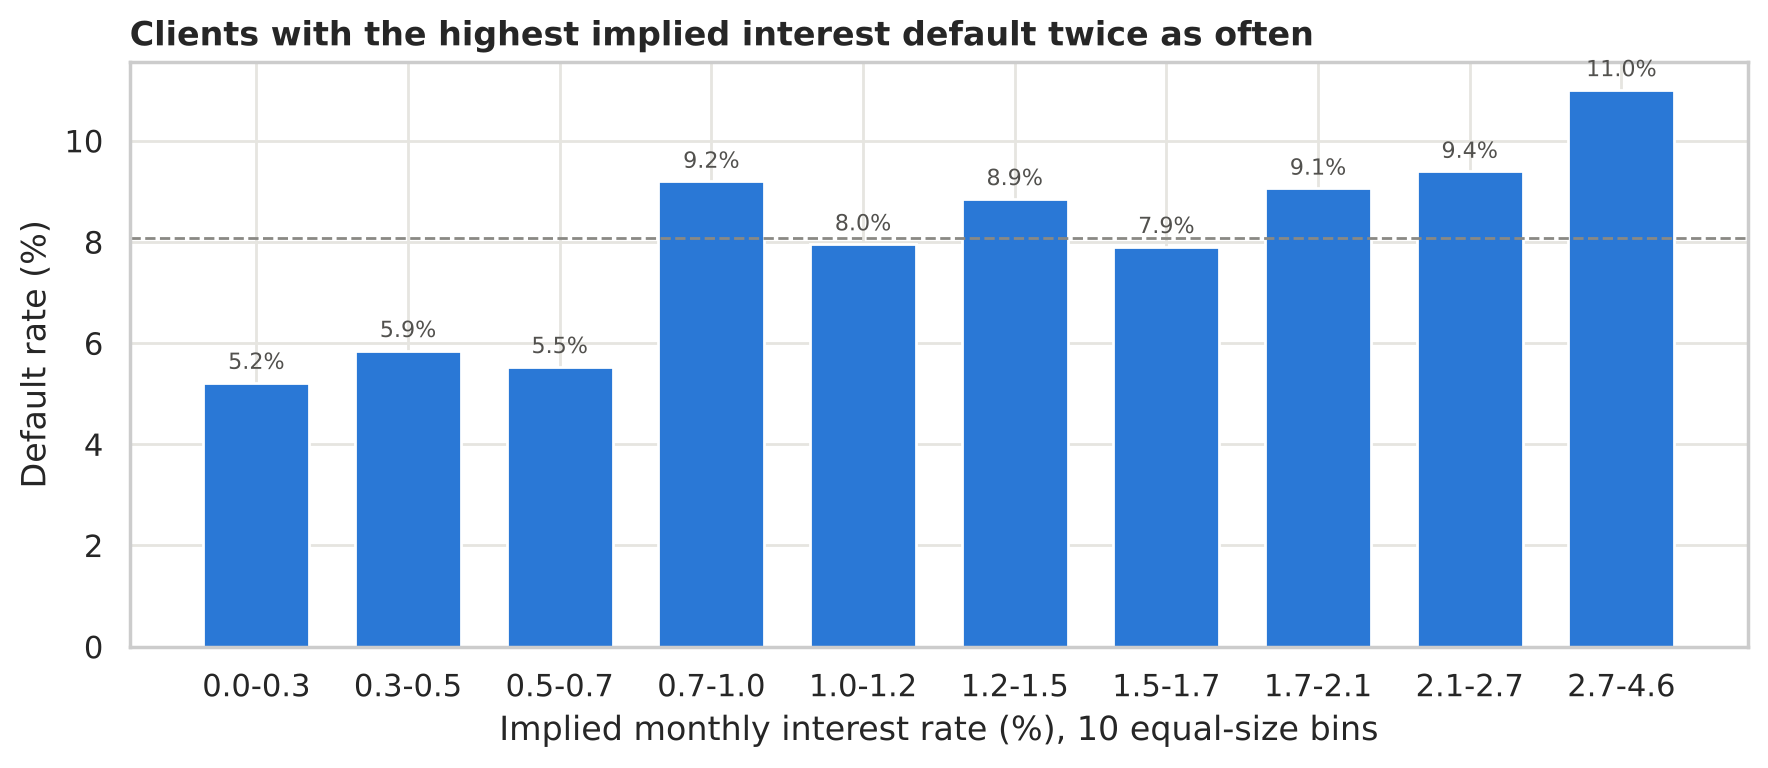

In [17]:
g = chk.groupby(pd.qcut(chk["RATE_GUESS"], 10), observed=True)["TARGET"].mean() * 100
labels = [f"{iv.left*100:.1f}-{iv.right*100:.1f}" for iv in g.index]

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(labels, g.values, color="#2a78d6", width=0.7)
ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=8, color="#52514e")
ax.axhline(train["TARGET"].mean() * 100, color="#8a8984", ls="--", lw=1)
ax.set_xlabel("Implied monthly interest rate (%), 10 equal-size bins")
ax.set_ylabel("Default rate (%)")
ax.set_title("Clients with the highest implied interest default twice as often")
plt.tight_layout(); plt.show()

**What we see:** from about 5% default with the cheapest loans to 11% with the most expensive ones. The bank was already pricing the risk, and now the model can see that price.

### 9.2 Does it improve the CV?

In [18]:
p5 = {**PARAMS, **tuning["+ learning_rate=0.02"]}
for name, groups in {"tuned + implied rate": [add_ratios, add_rates],
                     "tuned + implied rate + payment signals": [add_ratios, add_rates, add_payment_signals]}.items():
    r = run_cv(*build_xy_fe(groups), params=p5, verbose=False)
    tune_res[name] = r
    print(f"{name:40s} CV AUC {r['auc']:.4f}  ({r['auc'] - tune_res['+ learning_rate=0.02']['auc']:+.4f} vs tuned)")

tuned + implied rate                     CV AUC 0.7646  (+0.0028 vs tuned)


tuned + implied rate + payment signals   CV AUC 0.7652  (+0.0034 vs tuned)


**+0.003** over the tuned model: the largest single gain since `CREDIT_TERM`, from one idea about how loans work.

**Ideas that did *not* work** (tested in a separate script with the same folds, not kept):
- **Comparison with the client's group** (income, credit and `EXT_SOURCE` relative to the median of their sector, occupation, education and income type): 0.7604, worse.
- **"Similar clients" (KNN target)**: default rate of the 200 nearest clients in `EXT_SOURCE` + `CREDIT_TERM`, computed inside each fold without ever using the client's own answer: 0.7604, worse. LightGBM already learns those neighbourhoods by itself.

In [19]:
best = tune_res["tuned + implied rate + payment signals"]
log += [dict(exp=11, version="+ implied interest rate + payment signals", cv_auc=best["auc"], fold_std=best["fold_std"])]
log_df = pd.DataFrame(log).set_index("exp")
log_df["vs_exp2"] = log_df["cv_auc"] - r2["auc"]
display(log_df.round(4))

sub = sample_sub.copy()
assert (sub["SK_ID_CURR"].values == test["SK_ID_CURR"].values).all()
sub["TARGET"] = best["pred_test"]
assert sub["TARGET"].between(0, 1).all() and sub["TARGET"].notna().all() and len(sub) == len(sample_sub)
sub.to_csv("output/submission_v4_lgbm_rates.csv", index=False)
print(f"Saved output/submission_v4_lgbm_rates.csv  |  CV AUC {best['auc']:.4f}")

,version,cv_auc,fold_std,vs_exp2
exp,,,,
0,"Tutorial (RF, 5 features, 70/30 split)",0.6690,NaN,-0.0809
1,"LightGBM, all features, no cleaning",0.7492,0.0032,-0.0007
2,+ Phase 2 cleaning,0.7499,0.0028,0.0000
3,+ drop FLAG_EMP_PHONE,0.7493,0.0035,-0.0006
4,+ A: EXT_SOURCE combinations,0.7495,0.0042,-0.0004
5,+ B: financial ratios <- kept,0.7577,0.0032,0.0078
6,+ C: time ratios,0.7491,0.0037,-0.0008
7,+ D: N_MISSING,0.7499,0.0036,-0.0000
8,+ E: count encoding,0.7497,0.0037,-0.0002


Saved output/submission_v4_lgbm_rates.csv  |  CV AUC 0.7652


## 10. Phase 5-6: a second model (CatBoost) and the blend

**CatBoost** is another gradient-boosting library, with two differences from LightGBM: it builds **symmetric trees** (every level asks the same question) and it encodes categories with its own **ordered target statistics**, which suits columns like `ORGANIZATION_TYPE`. Same features, same folds.

> Requires `pip install catboost` (added to `requirements.txt`).

> **Why combine two models:** two good doctors who trained at different schools make *different* mistakes. Averaging their opinions cancels part of those mistakes. It only helps if the models are good **and** not identical.

In [20]:
from catboost import CatBoostClassifier

def run_cv_catboost(X, y, X_test, n_splits=5):
    cat_cols = X.select_dtypes(["category", "object"]).columns.tolist()
    X, X_test = X.copy(), X_test.copy()
    for c in cat_cols:                                   # CatBoost wants text categories without NaN
        X[c] = X[c].astype("object").fillna("MISSING").astype(str)
        X_test[c] = X_test[c].astype("object").fillna("MISSING").astype(str)
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    oof, pred_test, fold_auc = np.zeros(len(X)), np.zeros(len(X_test)), []
    for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y)):
        model = CatBoostClassifier(iterations=5000, learning_rate=0.05, depth=6, eval_metric="AUC",
                                   random_seed=SEED, od_type="Iter", od_wait=200, verbose=0,
                                   cat_features=cat_cols)
        model.fit(X.iloc[tr_idx], y.iloc[tr_idx], eval_set=(X.iloc[va_idx], y.iloc[va_idx]), use_best_model=True)
        oof[va_idx] = model.predict_proba(X.iloc[va_idx])[:, 1]
        pred_test += model.predict_proba(X_test)[:, 1] / n_splits
        fold_auc.append(roc_auc_score(y.iloc[va_idx], oof[va_idx]))
        print(f"Fold {fold + 1}: AUC {fold_auc[-1]:.4f}  ({model.get_best_iteration()} trees)")
    auc = roc_auc_score(y, oof)
    print(f"OOF AUC: {auc:.4f}   (fold std: {np.std(fold_auc):.4f})")
    return dict(auc=auc, fold_std=np.std(fold_auc), oof=oof, pred_test=pred_test)

X10, y10, X10_test = build_xy_fe([add_ratios, add_rates, add_payment_signals])
r_cb = run_cv_catboost(X10, y10, X10_test)
r_lgb = tune_res["tuned + implied rate + payment signals"]
print(f"\nLightGBM {r_lgb['auc']:.4f} | CatBoost {r_cb['auc']:.4f} | "
      f"correlation of their predictions: {np.corrcoef(r_lgb['oof'], r_cb['oof'])[0, 1]:.3f}")

Fold 1: AUC 0.7625  (1327 trees)


Fold 2: AUC 0.7650  (957 trees)


Fold 3: AUC 0.7685  (951 trees)


Fold 4: AUC 0.7612  (827 trees)


Fold 5: AUC 0.7651  (965 trees)
OOF AUC: 0.7644   (fold std: 0.0025)

LightGBM 0.7652 | CatBoost 0.7644 | correlation of their predictions: 0.965


Both models score almost the same and their predictions are highly correlated (~0.96), but not identical: there is room for the blend.

**Choosing the weight.** We try several weights on the out-of-fold predictions. If the curve is flat around the top, we take the simple 50/50: tuning the weight to the fourth decimal would be fitting noise.

In [21]:
weights = np.round(np.arange(0, 1.01, 0.1), 1)
blend_auc = [roc_auc_score(y10, w * r_lgb["oof"] + (1 - w) * r_cb["oof"]) for w in weights]
display(pd.DataFrame({"weight_LightGBM": weights, "weight_CatBoost": 1 - weights, "CV AUC": blend_auc}).round(4).T)

W = 0.5
blend_oof = W * r_lgb["oof"] + (1 - W) * r_cb["oof"]
blend_test = W * r_lgb["pred_test"] + (1 - W) * r_cb["pred_test"]
blend_cv = roc_auc_score(y10, blend_oof)
print(f"Blend 50/50 CV AUC: {blend_cv:.4f}  ({blend_cv - r_lgb['auc']:+.4f} vs LightGBM alone)")

,0,1,2,3,4,5,6,7,8,9,10
weight_LightGBM,0.0000,0.1000,0.2000,0.3000,0.4000,0.5000,0.6000,0.7000,0.8000,0.9000,1.0000
weight_CatBoost,1.0000,0.9000,0.8000,0.7000,0.6000,0.5000,0.4000,0.3000,0.2000,0.1000,0.0000
CV AUC,0.7644,0.7651,0.7657,0.7661,0.7664,0.7665,0.7665,0.7664,0.7662,0.7658,0.7652


Blend 50/50 CV AUC: 0.7665  (+0.0013 vs LightGBM alone)


In [22]:
log += [dict(exp=12, version="CatBoost (same features)", cv_auc=r_cb["auc"], fold_std=r_cb["fold_std"]),
        dict(exp=13, version="Blend 50/50 LightGBM + CatBoost", cv_auc=blend_cv, fold_std=np.nan)]
log_df = pd.DataFrame(log).set_index("exp")
log_df["vs_exp2"] = log_df["cv_auc"] - r2["auc"]
display(log_df.round(4))

sub = sample_sub.copy()
assert (sub["SK_ID_CURR"].values == test["SK_ID_CURR"].values).all()
sub["TARGET"] = blend_test
assert sub["TARGET"].between(0, 1).all() and sub["TARGET"].notna().all() and len(sub) == len(sample_sub)
sub.to_csv("output/submission_v5_blend_lgbm_catboost.csv", index=False)
print(f"Saved output/submission_v5_blend_lgbm_catboost.csv  |  CV AUC {blend_cv:.4f}")

,version,cv_auc,fold_std,vs_exp2
exp,,,,
0,"Tutorial (RF, 5 features, 70/30 split)",0.6690,NaN,-0.0809
1,"LightGBM, all features, no cleaning",0.7492,0.0032,-0.0007
2,+ Phase 2 cleaning,0.7499,0.0028,0.0000
3,+ drop FLAG_EMP_PHONE,0.7493,0.0035,-0.0006
4,+ A: EXT_SOURCE combinations,0.7495,0.0042,-0.0004
5,+ B: financial ratios <- kept,0.7577,0.0032,0.0078
6,+ C: time ratios,0.7491,0.0037,-0.0008
7,+ D: N_MISSING,0.7499,0.0036,-0.0000
8,+ E: count encoding,0.7497,0.0037,-0.0002


Saved output/submission_v5_blend_lgbm_catboost.csv  |  CV AUC 0.7665


**Next steps:** seed averaging (train each model with several seeds and average) and, if time allows, one more round of feature ideas.